<a href="https://colab.research.google.com/github/arjunnamburi/ml_death_overs_ipl/blob/main/test_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ===== T0. Setup and load (COPY-PASTE) =====
import json, os, time, datetime, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')
DATA = '/content/drive/MyDrive/IPL PROJECT ALL DOCS/data/'

df = pd.read_parquet(DATA + 'ipl_features.parquet')
with open(DATA + 'feature_list.json') as f: meta = json.load(f)
with open(DATA + 'freeze.json') as f:       FZ = json.load(f)
with open(DATA + 'calibration.json') as f:  CALJ = json.load(f)

FEATURES, CAT_FEATURES, CLASSES = meta['features'], meta['categorical'], meta['classes']
HIST = sum(meta['hist_features'].values(), [])
NUM = [c for c in FEATURES if c not in CAT_FEATURES]
NUM_H = NUM + HIST                        # B2-hist numeric inputs (82)
FEAT_HIST = list(FEATURES) + HIST         # X-hist inputs (87)
K = len(CLASSES)

# legal balls of 2008-2026; rain-affected matches have split 'rain' and stay out
d = df[(df['y'] >= 0) & df['split'].isin(['train', 'val', 'test'])].copy()
d['y'] = d['y'].astype(int)
for c in CAT_FEATURES:
    if not isinstance(d[c].dtype, pd.CategoricalDtype):
        d[c] = d[c].astype('category')

TR    = (d['split'] == 'train').to_numpy()     # 2008-2024: used only to pick X-hist's tree count
VA    = (d['split'] == 'val').to_numpy()       # 2025
FIT   = TR | VA                                # 2008-2025: every final model is refit here
TE    = (d['split'] == 'test').to_numpy()      # 2026: scored once, in T7
DEATH = (d['match_phase'] == 'death').to_numpy()

Mounted at /content/drive


In [2]:
# ===== T1. Checks (COPY-PASTE) =====
print('1.', d['split'].value_counts().to_dict())                               # expect train 244269, val 15809, test 16282
print('2. 2026 matches:', d.loc[TE, 'match_id'].nunique(),
      '| 2026 death balls:', int((TE & DEATH).sum()))                          # expect 71 | 3583
print('3. refit seasons:', d.loc[FIT, 'year'].min(), '-', d.loc[FIT, 'year'].max(),
      '| test seasons:', d.loc[TE, 'year'].unique().tolist())                  # expect 2008 - 2025 | [2026]
print('4. X-hist features = freeze.json:', FEAT_HIST == FZ['final_models']['X-hist']['features'], len(FEAT_HIST))   # True 87
print('5. 2026 history NaN (target_vs_par left out):',
      int(d.loc[TE, [c for c in HIST if c != 'target_vs_par']].isna().sum().sum()))                                  # expect 0
print('6. 2026 calibrator sizes:', len(CALJ['B2-hist']['a_for_2026']), len(CALJ['B2-hist']['b_for_2026']))         # expect 7 7
print('7. most splits per match:', d.groupby('match_id')['split'].nunique().max())                                  # expect 1

1. {'train': 244269, 'test': 16282, 'val': 15809}
2. 2026 matches: 71 | 2026 death balls: 3583
3. refit seasons: 2008 - 2025 | test seasons: [2026]
4. X-hist features = freeze.json: True 87
5. 2026 history NaN (target_vs_par left out): 0
6. 2026 calibrator sizes: 7 7
7. most splits per match: 1


In [3]:
# ===== T2. Helpers (COPY-PASTE: copies of models.ipynb functions) =====
EPS = 1e-15
def per_ball_logloss(P, y):
    return -np.log(np.clip(P[np.arange(len(y)), y], EPS, 1))

def per_ball_brier(P, y):
    O = np.zeros_like(P); O[np.arange(len(y)), y] = 1
    return ((P - O) ** 2).sum(axis=1)

def slice_paired(la, lb, mask, match, n_boot=2000, z_bonf=3.254, seed=0):
    """Mean of (la - lb) over the slice, 95% match-bootstrap interval, SE, Bonferroni flag. lb = 0 gives one model's interval."""
    diff, m = (la - lb)[mask], match[mask]
    codes, _ = pd.factorize(m)
    s, c = np.bincount(codes, weights=diff), np.bincount(codes)
    idx = np.random.default_rng(seed).integers(0, len(s), size=(n_boot, len(s)))
    boot = s[idx].sum(axis=1) / c[idx].sum(axis=1)
    mean, se = diff.mean(), boot.std()
    low, high = np.percentile(boot, [2.5, 97.5])
    return mean, low, high, se, abs(mean) > z_bonf * se

# --- B0 / B1 ---
def fit_freq(y): return np.bincount(y, minlength=K) / len(y)

WKT_BAND = pd.cut(d['c_team_wickets'], bins=[-1, 2, 5, 7, 9], labels=['0-2', '3-5', '6-7', '8-9'])
d['cell'] = d['match_phase'].astype(str) + ' | ' + WKT_BAND.astype(str) + ' wkts | inn ' + d['innings'].astype(str)
ALL_CELLS = [f'{ph} | {w} wkts | inn {i}' for ph in ['powerplay', 'middle', 'death']
             for w in ['0-2', '3-5', '6-7', '8-9'] for i in [1, 2]]

def fit_b1(rows, k=100):
    counts = (pd.crosstab(d.loc[rows, 'cell'], d.loc[rows, 'y'])
                .reindex(index=ALL_CELLS, columns=range(K), fill_value=0))
    prior = fit_freq(d.loc[rows, 'y'].values)
    n = counts.sum(axis=1).values[:, None]
    probs = np.where(n + k > 0, (counts.values + k * prior) / np.maximum(n + k, 1), prior)
    return pd.DataFrame(probs, index=ALL_CELLS, columns=CLASSES), counts.sum(axis=1)

def predict_b1(table, rows): return table.loc[d.loc[rows, 'cell']].values

# --- B2-hist ---
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning

def missing_groups(rows, cols):
    miss = d.loc[rows, cols].isna()
    miss = miss.loc[:, miss.any()]
    groups = {}
    for c in miss.columns:
        groups.setdefault(miss[c].values.tobytes(), []).append(c)
    return list(groups.values())

def fit_prep(rows, num, cat):
    X = d.loc[rows, num]
    lo, hi = X.quantile(0.005), X.quantile(0.995)
    few = X.nunique() <= 20
    lo[few], hi[few] = -np.inf, np.inf
    Xc = X.clip(lo, hi, axis=1)
    return {'num': num, 'cat': cat, 'lo': lo, 'hi': hi, 'mean': Xc.mean(), 'std': Xc.std().replace(0, 1),
            'groups': missing_groups(rows, num)}

def transform(prep, rows):
    X = d.loc[rows, prep['num']]
    Z = ((X.clip(prep['lo'], prep['hi'], axis=1) - prep['mean']) / prep['std']).fillna(0)
    flags = pd.DataFrame({'miss_' + g[0]: X[g[0]].isna().astype(float) for g in prep['groups']}, index=X.index)
    onehot = pd.get_dummies(d.loc[rows, prep['cat']], dtype=float)
    return pd.concat([Z, flags, onehot], axis=1)

def fit_lr(X, y, C=1.0):
    m = LogisticRegression(C=C, max_iter=3000)
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        m.fit(X, y)
    return m

def to_logits(P, eps=1e-12): return np.log(np.clip(P, eps, 1))
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True); E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)
def apply_vector(P, a, b): return softmax(to_logits(P) * a + b)

# --- X-hist ---
import xgboost as xgb
XP = FZ['final_models']['X-hist']['params']
BEST = dict(max_depth=XP['max_depth'], min_child_weight=XP['min_child_weight'])
BASE_PARAMS = dict(objective='multi:softprob', eval_metric='mlogloss', tree_method='hist',
                   device='cuda', enable_categorical=True,
                   learning_rate=XP['learning_rate'], subsample=XP['subsample'],
                   colsample_bytree=XP['colsample_bytree'], random_state=0)

def fit_xgb_es(feats, fit_rows, stop_rows, **params):
    m = xgb.XGBClassifier(**BASE_PARAMS, **params, n_estimators=5000, early_stopping_rounds=50)
    m.fit(d.loc[fit_rows, feats], d.loc[fit_rows, 'y'],
          eval_set=[(d.loc[stop_rows, feats], d.loc[stop_rows, 'y'])], verbose=200)
    return m, m.best_iteration + 1, m.best_score

def fit_xgb_fixed(feats, rows, n_trees, **params):
    m = xgb.XGBClassifier(**BASE_PARAMS, **params, n_estimators=n_trees)
    m.fit(d.loc[rows, feats], d.loc[rows, 'y'], verbose=False)
    return m

print('xgboost', xgb.__version__, '| frozen X-hist settings:', BEST, XP)   # expect depth 4, mcw 100, lr .05, sub/col .8

xgboost 3.4.1 | frozen X-hist settings: {'max_depth': 4, 'min_child_weight': 100} {'max_depth': 4, 'min_child_weight': 100, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8}


In [4]:
# ===== T3. B0 and B1 refit on 2008-2025 (COPY-PASTE) =====
P = {}                                              # 2026 probabilities per model; scored only in T7
p_b0 = fit_freq(d.loc[FIT, 'y'].to_numpy())
P['B0'] = np.tile(p_b0, (TE.sum(), 1))
b1_table, b1_n = fit_b1(FIT, k=100)
P['B1'] = predict_b1(b1_table, TE)
print('B0 (2008-2025, %):', dict(zip(CLASSES, (100 * p_b0).round(2))))   # expect about 30.8 / 39.8 / 6.6 / 0.3 / 12.1 / 5.3 / 5.1
print('B1 cells with training balls:', int((b1_n > 0).sum()), 'of 24')     # expect 21 or 22

B0 (2008-2025, %): {'0': np.float64(30.77), '1': np.float64(39.82), '2': np.float64(6.56), '3': np.float64(0.31), '4': np.float64(12.13), '6': np.float64(5.3), 'Wicket': np.float64(5.1)}
B1 cells with training balls: 21 of 24


In [5]:
# ===== T4. B2-hist refit on 2008-2025 + the frozen 2026 calibrator (TYPE IT) =====
prep_h26 = fit_prep(FIT, NUM_H, CAT_FEATURES)                    # learned on 2008-2025 rows only
X_fit, X_26 = transform(prep_h26, FIT), transform(prep_h26, TE)  # 2026 gets the 2008-2025 numbers
assert list(X_fit.columns) == list(X_26.columns), 'one-hot columns differ'

t0 = time.time()
b2h26 = fit_lr(X_fit.values, d.loc[FIT, 'y'].to_numpy())
print('B2-hist refit:', round(time.time() - t0), 's |', int(b2h26.n_iter_[0]), 'iterations |',
      X_fit.shape[1], 'inputs')                                  # expect about 150 iterations | about 118 inputs

P['B2-hist (raw)'] = b2h26.predict_proba(X_26.values)            # kept only for a descriptive check
a26 = np.array(CALJ['B2-hist']['a_for_2026'])
b26 = np.array(CALJ['B2-hist']['b_for_2026'])
P['B2-hist +V'] = apply_vector(P['B2-hist (raw)'], a26, b26)     # the frozen model
print('a used:', dict(zip(['0', '1', '2', '3', '4', '6', 'W'], a26.round(3))))   # expect .778 1.156 .734 .140 .779 .644 1.003

B2-hist refit: 47 s | 175 iterations | 118 inputs
a used: {'0': np.float64(0.778), '1': np.float64(1.156), '2': np.float64(0.734), '3': np.float64(0.14), '4': np.float64(0.779), '6': np.float64(0.644), 'W': np.float64(1.003)}


In [6]:
# ===== T5. X-hist: tree count from 2025, refit on 2008-2025 (TYPE IT) =====
t0 = time.time()
m_es, n26, s25 = fit_xgb_es(FEAT_HIST, TR, VA, **BEST)          # train 2008-2024, stop on 2025 (patience 50)
curve = m_es.evals_result()['validation_0']['mlogloss']
print(f'trees for 2026: {n26} | best 2025 log-loss {s25:.4f}')
if len(curve) >= 340:
    print(f'reproduction: 2025 log-loss at 340 trees {curve[339]:.4f}')   # expect 1.4727 (frozen X-hist), +-0.0002 on GPU

x26 = fit_xgb_fixed(FEAT_HIST, FIT, n26, **BEST)                 # same settings, one more season of data
P['X-hist'] = x26.predict_proba(d.loc[TE, FEAT_HIST])
print('done in', round(time.time() - t0), 's')

[0]	validation_0-mlogloss:1.53544
[200]	validation_0-mlogloss:1.47252
[350]	validation_0-mlogloss:1.47280
trees for 2026: 301 | best 2025 log-loss 1.4723
reproduction: 2025 log-loss at 340 trees 1.4727
done in 30 s


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [19:53:56] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


In [7]:
# ===== T6. Checks and save before scoring (COPY-PASTE) =====
import joblib
for name, Pm in P.items():
    print(f'{name:14s} {Pm.shape} | rows sum to 1: {np.allclose(Pm.sum(axis=1), 1)} | smallest p {Pm.min():.1e}')
    # expect (16282, 7) | True | smallest p above 0 for every model

v = d.loc[TE]
B26 = pd.DataFrame({
    'match_id': v['match_id'].to_numpy(), 'innings2': (v['innings'] == 2).to_numpy(),
    'over0': v['c_team_balls'].to_numpy() // 6, 'wkts_down': v['c_team_wickets'].to_numpy(),
    'balls_faced': v['c_batter_balls'].to_numpy(), 'rrr': v['required_run_rate'].to_numpy(),
    'bat_pos': v['bat_pos_group'].astype(str).to_numpy(),
    'prev_y': d.groupby(['match_id', 'innings'])['y'].shift(1).loc[v.index].to_numpy(),
    'free_hit': v['is_free_hit'].astype(bool).to_numpy(), 'death': DEATH[TE],
    'batter': v['batter'].astype(str).to_numpy(), 'bowler': v['bowler'].astype(str).to_numpy(),
    'y': v['y'].to_numpy()}, index=v.index)
TAGS = {'X-hist': 'x', 'B2-hist +V': 'l', 'B1': 'b1', 'B0': 'b0', 'B2-hist (raw)': 'lr'}
for name, tag in TAGS.items():
    for k in range(K):
        B26[f'p{tag}_{k}'] = P[name][:, k]
B26.to_parquet(DATA + 'bundle_2026.parquet')

x26.save_model(DATA + 'xgb_X-hist_2026.json')
joblib.dump({'b2h26': b2h26, 'prep_h26': prep_h26, 'b1_table': b1_table, 'p_b0': p_b0}, DATA + 'models_2026.joblib')
with open(DATA + 'test_2026_config.json', 'w') as f:
    json.dump({'saved_on': str(datetime.datetime.now()), 'refit_rows': int(FIT.sum()), 'test_rows': int(TE.sum()),
               'xhist_trees_2026': int(n26), 'xhist_2025_at_best': float(s25), 'xgboost': xgb.__version__,
               'b2hist_iterations': int(b2h26.n_iter_[0]), 'b2hist_inputs': int(X_fit.shape[1])}, f, indent=2)
print('saved bundle_2026.parquet', B26.shape)                    # expect (16282, 48)

B0             (16282, 7) | rows sum to 1: True | smallest p 3.1e-03
B1             (16282, 7) | rows sum to 1: True | smallest p 6.3e-04
B2-hist (raw)  (16282, 7) | rows sum to 1: True | smallest p 1.6e-04
B2-hist +V     (16282, 7) | rows sum to 1: True | smallest p 1.3e-03
X-hist         (16282, 7) | rows sum to 1: True | smallest p 4.1e-04
saved bundle_2026.parquet (16282, 48)


In [8]:
# ===== T7. THE 2026 SCORE: run once (COPY-PASTE) =====
B26 = pd.read_parquet(DATA + 'bundle_2026.parquet')              # always score the saved predictions
TAGS = {'X-hist': 'x', 'B2-hist +V': 'l', 'B1': 'b1', 'B0': 'b0', 'B2-hist (raw)': 'lr'}
P = {name: B26[[f'p{tag}_{k}' for k in range(K)]].to_numpy() for name, tag in TAGS.items()}
y26, match26, dth26 = B26['y'].to_numpy().astype(int), B26['match_id'].to_numpy(), B26['death'].to_numpy()
ALL26 = np.ones(len(y26), bool)

ORDER = ['B0', 'B1', 'B2-hist (raw)', 'B2-hist +V', 'X-hist']
L  = {m: per_ball_logloss(P[m], y26) for m in ORDER}
BR = {m: per_ball_brier(P[m], y26) for m in ORDER}

rows = []
for m in ORDER:
    for sl, mask in [('all', ALL26), ('death', dth26)]:
        mean, lo, hi, _, _ = slice_paired(L[m], 0, mask, match26)
        rows.append({'model': m, 'slice': sl, 'balls': int(mask.sum()),
                     'logloss': mean, 'll_low': lo, 'll_high': hi, 'brier': BR[m][mask].mean()})
RES26 = pd.DataFrame(rows)

R25 = pd.read_csv(DATA + 'results.csv').query("split == 'val'")
R25['model'] = R25['model'].replace({'B2-hist': 'B2-hist (raw)', 'B2-hist +V(A)': 'B2-hist +V'})
R25 = R25.drop_duplicates(['model', 'slice'], keep='last')[['model', 'slice', 'logloss']]
RES26 = RES26.merge(R25.rename(columns={'logloss': 'logloss 2025'}), on=['model', 'slice'], how='left')
display(RES26.round(4))
RES26.to_csv(DATA + 'results_2026.csv', index=False)

,model,slice,balls,logloss,ll_low,ll_high,brier,logloss 2025
0,B0,all,16282,1.5461,1.5311,1.5601,0.7421,1.5391
1,B0,death,3583,1.6434,1.6195,1.6676,0.7693,1.6682
2,B1,all,16282,1.5204,1.5053,1.5347,0.7282,1.5119
3,B1,death,3583,1.6017,1.5805,1.6237,0.7565,1.6018
4,B2-hist (raw),all,16282,1.4844,1.4705,1.4982,0.7170,1.4785
5,B2-hist (raw),death,3583,1.5858,1.5633,1.6076,0.7520,1.5772
6,B2-hist +V,all,16282,1.4813,1.4681,1.4943,0.7162,1.4762
7,B2-hist +V,death,3583,1.5764,1.5547,1.5976,0.7493,1.5722
8,X-hist,all,16282,1.4787,1.4653,1.4919,0.7149,1.4727
9,X-hist,death,3583,1.5680,1.5460,1.5899,0.7453,1.5590


In [9]:
# ===== T8. Paired tests on 2026 (COPY-PASTE) =====
PAIRS = [('X-hist', 'B2-hist +V'), ('X-hist', 'B1'), ('B2-hist +V', 'B1'), ('B1', 'B0'),   # frozen
         ('X-hist', 'B0'), ('B2-hist +V', 'B2-hist (raw)')]                               # descriptive
rows = []
for i, (a, b) in enumerate(PAIRS):
    for sl, mask in [('all', ALL26), ('death', dth26)]:
        diff, lo, hi, _, _ = slice_paired(L[a], L[b], mask, match26)
        rows.append({'A': a, 'B': b, 'slice': sl, 'diff': diff, 'low': lo, 'high': hi,
                     'verdict': 'A better' if hi < 0 else ('B better' if lo > 0 else "can't tell"),
                     'in freeze.json': i < 4})
PAIR26 = pd.DataFrame(rows)
display(PAIR26.round(4))
PAIR26.to_csv(DATA + 'paired_2026.csv', index=False)

,A,B,slice,diff,low,high,verdict,in freeze.json
0,X-hist,B2-hist +V,all,-0.0026,-0.0047,-0.0005,A better,True
1,X-hist,B2-hist +V,death,-0.0084,-0.0143,-0.0029,A better,True
2,X-hist,B1,all,-0.0417,-0.0482,-0.0358,A better,True
3,X-hist,B1,death,-0.0338,-0.0468,-0.0212,A better,True
4,B2-hist +V,B1,all,-0.0391,-0.0455,-0.0331,A better,True
5,B2-hist +V,B1,death,-0.0254,-0.0367,-0.0147,A better,True
6,B1,B0,all,-0.0257,-0.0297,-0.0219,A better,True
7,B1,B0,death,-0.0417,-0.0513,-0.0318,A better,True
8,X-hist,B0,all,-0.0674,-0.0746,-0.0607,A better,False
9,X-hist,B0,death,-0.0755,-0.0924,-0.0593,A better,False


In [10]:
# ===== T9. Pre-registered 2026 checks (TYPE IT) =====
wk, pos = B26['wkts_down'].to_numpy(), B26['bat_pos'].to_numpy()
inn2, rrr = B26['innings2'].to_numpy(), B26['rrr'].to_numpy()       # rrr is NaN in innings 1 -> False there

PRE = {   # claim: (A, B, which balls, 2025 diff)
    'death':            ('X-hist', 'B2-hist +V', dth26,                  -0.0131),
    '6+ wickets down':  ('X-hist', 'B2-hist +V', wk >= 6,                -0.0292),
    'finishers':        ('X-hist', 'B2-hist +V', pos == 'finisher',      -0.0147),
    'easy chase RRR<8': ('X-hist', 'B2-hist +V', inn2 & (rrr < 8),       -0.0076),
    '3-5 wickets down': ('X-hist', 'B2-hist +V', (wk >= 3) & (wk <= 5),  -0.0037),
    'all balls':        ('X-hist', 'B1',         ALL26,                  -0.0393),
}
rows = []
for claim, (a, b, mask, d25) in PRE.items():
    diff, lo, hi, se, bonf = slice_paired(L[a], L[b], mask, match26)
    rows.append({'claim': f'{a} beats {b}: {claim}', 'balls': int(mask.sum()), '2025 diff': d25,
                 '2026 diff': diff, 'low': lo, 'high': hi, 'Bonferroni (44)': 'Y' if bonf else '',
                 'verdict': 'confirmed' if hi < 0 else ('reversed' if lo > 0 else 'not confirmed')})
PRE26 = pd.DataFrame(rows).set_index('claim')
display(PRE26.round(4))
PRE26.to_csv(DATA + 'preregistered_2026.csv')

,balls,2025 diff,2026 diff,low,high,Bonferroni (44),verdict
claim,,,,,,,
X-hist beats B2-hist +V: death,3583,-0.0131,-0.0084,-0.0143,-0.0029,,confirmed
X-hist beats B2-hist +V: 6+ wickets down,1721,-0.0292,-0.0141,-0.0243,-0.0037,,confirmed
X-hist beats B2-hist +V: finishers,2986,-0.0147,-0.0034,-0.0096,0.0028,,not confirmed
X-hist beats B2-hist +V: easy chase RRR<8,2049,-0.0076,-0.0039,-0.0093,0.0010,,not confirmed
X-hist beats B2-hist +V: 3-5 wickets down,5661,-0.0037,0.0011,-0.0022,0.0043,,not confirmed
X-hist beats B1: all balls,16282,-0.0393,-0.0417,-0.0482,-0.0358,Y,confirmed


In [11]:
# ===== T10. Slices on 2026 (COPY-PASTE) =====
over0, faced, prev = B26['over0'].to_numpy(), B26['balls_faced'].to_numpy(), B26['prev_y'].to_numpy()
FAMILIES = {
    'all':              {'all balls': ALL26},
    'phase':            {'powerplay': over0 < 6, 'middle': (over0 >= 6) & (over0 < 15), 'death': over0 >= 15},
    'innings':          {'1': ~inn2, '2': inn2},
    'wickets down':     {'0-2': wk <= 2, '3-5': (wk >= 3) & (wk <= 5), '6+': wk >= 6},
    'batting position': {g: pos == g for g in sorted(set(pos))},
    'chase (inn 2)':    {'RRR <8': inn2 & (rrr < 8), 'RRR 8-12': inn2 & (rrr >= 8) & (rrr < 12),
                         'RRR 12-18': inn2 & (rrr >= 12) & (rrr <= 18)},
    'balls faced':      {'0-9': faced <= 9, '10-29': (faced >= 10) & (faced <= 29), '30+': faced >= 30},
    'previous ball':    {'dot': prev == 0, '1-3 runs': np.isin(prev, [1, 2, 3]),
                         'boundary': np.isin(prev, [4, 5]), 'wicket': prev == 6},
}
print('death mask agrees with bundle:', (FAMILIES['phase']['death'] == dth26).mean())   # expect 1.0

LX, LL, LB = L['X-hist'], L['B2-hist +V'], L['B1']
S25 = pd.read_csv(DATA + 'slices_2025.csv', dtype={'group': str}).set_index(['family', 'group'])
tot_XL = (LX - LL).sum()
rows = []
for fam, groups in FAMILIES.items():
    for g, m in groups.items():
        m = np.asarray(m, bool)
        xl, xb = slice_paired(LX, LL, m, match26), slice_paired(LX, LB, m, match26)
        rows.append({'family': fam, 'group': g, 'balls': int(m.sum()), 'matches': len(np.unique(match26[m])),
                     '% balls': 100 * m.mean(),
                     'LL X-hist': LX[m].mean(), 'LL B2h+V': LL[m].mean(), 'LL B1': LB[m].mean(),
                     'X-L 2025': S25['X-L'].get((fam, g), np.nan),
                     'X-L': xl[0], 'X-L low': xl[1], 'X-L high': xl[2], 'X-L bonf': 'Y' if xl[4] else '',
                     '% of X-L gain': 100 * (LX - LL)[m].sum() / tot_XL,
                     'X-B1': xb[0], 'X-B1 low': xb[1], 'X-B1 high': xb[2], 'X-B1 bonf': 'Y' if xb[4] else ''})
SL26 = pd.DataFrame(rows).set_index(['family', 'group'])
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
display(SL26.round({'% balls': 1, '% of X-L gain': 0, **{c: 4 for c in SL26.columns if c.startswith(('LL', 'X-'))}}))
SL26.to_csv(DATA + 'slices_2026.csv')

death mask agrees with bundle: 1.0


balls  matches  % balls  LL X-hist  LL B2h+V   LL B1  X-L 2025     X-L  X-L low  X-L high X-L bonf  % of X-L gain    X-B1  X-B1 low  X-B1 high X-B1 bonf
family           group                                                                                                                                                              
all              all balls  16282       71    100.0     1.4787    1.4813  1.5204   -0.0035 -0.0026  -0.0047   -0.0005                   100.0 -0.0417   -0.0482    -0.0358         Y
phase            powerplay   5112       71     31.4     1.4902    1.4924  1.5439   -0.0018 -0.0022  -0.0056    0.0012                    26.0 -0.0538   -0.0676    -0.0412         Y
                 middle      7587       71     46.6     1.4288    1.4290  1.4662   -0.0002 -0.0002  -0.0031    0.0025                     4.0 -0.0374   -0.0453    -0.0297         Y
                 death       3583       71     22.0     1.5680    1.5764  1.6017   -0.0131 -0.0084  -0.0143   -0.0029                    70.0 -0.0338   -0.0468    -0.0212         Y
innings          1           8479       71     52.1     1.4792    1.4814  1.5218   -0.0045 -0.0022  -0.0048    0.0004                    43.0 -0.0426   -0.0503    -0.0351         Y
                 2           7803       71     47.9     1.4781    1.4812  1.5189   -0.0025 -0.0031  -0.0064    0.0001                    57.0 -0.0408   -0.0495    -0.0322         Y
wickets down     0-2         8900       71     54.7     1.4755    1.4783  1.5278    0.0008 -0.0028  -0.0058    0.0002                    57.0 -0.0523   -0.0621    -0.0431         Y
                 3-5         5661       71     34.8     1.4718    1.4707  1.4943   -0.0037  0.0011  -0.0022    0.0043                   -14.0 -0.0225   -0.0314    -0.0131         Y
                 6+          1721       58     10.6     1.5178    1.5319  1.5683   -0.0292 -0.0141  -0.0243   -0.0037                    57.0 -0.0505   -0.0698    -0.0307         Y
batting position finisher    2986       70     18.3     1.4831    1.4865  1.5199   -0.0147 -0.0034  -0.0096    0.0028                    23.0 -0.0368   -0.0468    -0.0252         Y
                 middle      4409       71     27.1     1.4631    1.4648  1.4859   -0.0021 -0.0017  -0.0052    0.0019                    17.0 -0.0227   -0.0320    -0.0129         Y
                 tail         542       47      3.3     1.4249    1.4338  1.4700   -0.0218 -0.0089  -0.0268    0.0082                    11.0 -0.0451   -0.0745    -0.0157          
                 top         8345       71     51.3     1.4888    1.4913  1.5421    0.0004 -0.0025  -0.0055    0.0004                    48.0 -0.0533   -0.0635    -0.0437         Y
chase (inn 2)    RRR <8      2049       48     12.6     1.4339    1.4379  1.4652   -0.0076 -0.0039  -0.0093    0.0010                    19.0 -0.0313   -0.0461    -0.0166         Y
                 RRR 8-12    3763       58     23.1     1.4780    1.4782  1.5262    0.0015 -0.0003  -0.0048    0.0042                     2.0 -0.0482   -0.0618    -0.0355         Y
                 RRR 12-18   1525       38      9.4     1.5235    1.5294  1.5661   -0.0035 -0.0059  -0.0175    0.0035                    21.0 -0.0426   -0.0585    -0.0293         Y
balls faced      0-9         8248       71     50.7     1.4456    1.4462  1.4773   -0.0039 -0.0006  -0.0037    0.0026                    12.0 -0.0317   -0.0393    -0.0246         Y
                 10-29       6462       71     39.7     1.4967    1.4995  1.5469   -0.0027 -0.0027  -0.0053   -0.0003                    41.0 -0.0502   -0.0598    -0.0406         Y
                 30+         1572       68      9.7     1.5782    1.5909  1.6381   -0.0051 -0.0127  -0.0218   -0.0040                    47.0 -0.0598   -0.0812    -0.0410         Y
previous ball    dot         4485       71     27.5     1.4941    1.4986  1.5370   -0.0043 -0.0045  -0.0083   -0.0006                    47.0 -0.0429   -0.0528    -0.0339         Y
                 1-3 runs    7233       71    

In [12]:
# ===== T11. Failure modes (COPY-PASTE) =====
Z4 = 2.498
FAIL = {'RRR > 18': inn2 & (rrr > 18), 'free hit': B26['free_hit'].to_numpy()}
rows = []
for s, m in FAIL.items():
    xl, xb = slice_paired(LX, LL, m, match26, z_bonf=Z4), slice_paired(LX, LB, m, match26, z_bonf=Z4)
    rows.append({'slice': s, 'balls': int(m.sum()), 'matches': len(np.unique(match26[m])),
                 'LL X-hist': LX[m].mean(), 'LL B2h+V': LL[m].mean(), 'LL B1': LB[m].mean(),
                 'X-L': xl[0], 'X-L low': xl[1], 'X-L high': xl[2], 'X-L bonf': 'Y' if xl[4] else '',
                 'X-B1': xb[0], 'X-B1 low': xb[1], 'X-B1 high': xb[2], 'X-B1 bonf': 'Y' if xb[4] else ''})
display(pd.DataFrame(rows).set_index('slice').round(4))

OUT = {'0': 0, '1': 1, '4': 4, '6': 5, 'W': 6}
def calib_gap(Pm, mask):
    res = {}
    for name, k in OUT.items():
        hit = (y26 == k).astype(float)
        g, lo, hi, _, _ = slice_paired(Pm[:, k], hit, mask, match26)     # mean of (p_k - hit) = predicted - actual
        res[name] = (100 * g, 100 * lo, 100 * hi)
    return res

cal_rows = []
for s, m in {'all balls (reference)': ALL26, **FAIL}.items():
    for mod in ['X-hist', 'B2-hist +V', 'B1']:
        for o, (g, lo, hi) in calib_gap(P[mod], m).items():
            cal_rows.append({'slice': s, 'model': mod, 'outcome': o,
                             'actual %': 100 * (y26[m] == OUT[o]).mean(), 'predicted %': 100 * P[mod][m, OUT[o]].mean(),
                             'gap': g, 'low': lo, 'high': hi, 'clear': '*' if (hi < 0 or lo > 0) else ''})
CAL26 = pd.DataFrame(cal_rows)
print('Gap = predicted - actual, points (positive = over-predicted)')
display(CAL26.pivot_table(index=['slice', 'model'], columns='outcome', values='gap', aggfunc='first')[list(OUT)].round(2))
print('Gaps whose 95% interval excludes 0'); display(CAL26[CAL26['clear'] == '*'].round(2))
CAL26.to_csv(DATA + 'failure_calibration_2026.csv', index=False)

,balls,matches,LL X-hist,LL B2h+V,LL B1,X-L,X-L low,X-L high,X-L bonf,X-B1,X-B1 low,X-B1 high,X-B1 bonf
slice,,,,,,,,,,,,,
RRR > 18,466,24,1.5252,1.5385,1.5415,-0.0134,-0.0353,0.0075,,-0.0164,-0.0552,0.0216,
free hit,60,37,1.5793,1.5336,1.6966,0.0457,-0.0014,0.0914,,-0.1173,-0.3145,0.0596,


Gap = predicted - actual, points (positive = over-predicted)


outcome                              0     1     4      6     W
slice                 model                                    
RRR > 18              B1          0.80  1.22 -1.59  -1.80 -0.64
                      B2-hist +V -3.47  0.56  1.18   1.87 -0.25
                      X-hist     -1.27 -3.68  0.27   3.41  0.67
all balls (reference) B1          3.58  0.73 -2.01  -3.29 -0.13
                      B2-hist +V -0.67  0.76  0.55  -0.57 -0.17
                      X-hist     -0.95 -0.21  0.59   0.15  0.34
free hit              B1          1.85  9.55 -6.57 -12.77  5.80
                      B2-hist +V -8.75  6.16  1.93  -1.94  1.11
                      X-hist     -8.54  2.82 -0.72  -0.03  5.94

Gaps whose 95% interval excludes 0


,slice,model,outcome,actual %,predicted %,gap,low,high,clear
0,all balls (reference),X-hist,0,27.61,26.66,-0.95,-1.87,-0.05,*
8,all balls (reference),B2-hist +V,6,8.50,7.93,-0.57,-1.01,-0.10,*
10,all balls (reference),B1,0,27.61,31.18,3.58,2.44,4.65,*
12,all balls (reference),B1,4,14.05,12.04,-2.01,-2.65,-1.34,*
13,all balls (reference),B1,6,8.50,5.21,-3.29,-3.89,-2.69,*
18,RRR > 18,X-hist,6,8.58,12.00,3.41,0.32,6.51,*
34,free hit,X-hist,W,0.00,5.94,5.94,5.22,6.72,*
39,free hit,B2-hist +V,W,0.00,1.11,1.11,0.97,1.24,*
43,free hit,B1,6,18.33,5.56,-12.77,-23.82,-2.80,*
44,free hit,B1,W,0.00,5.80,5.80,5.24,6.37,*


All balls (points; gap = predicted - actual)


,actual 2025,actual 2026,X-hist gap 2025,X-hist gap 2026,B2-hist +V gap 2025,B2-hist +V gap 2026,B2-hist raw gap 2026,B1 gap 2026
0,26.99,27.61,-0.12,-0.95,-1.01,-0.67,-1.12,3.58
1,39.88,38.93,-1.89,-0.21,-0.94,0.76,0.10,0.73
2,5.95,5.51,-0.13,0.12,0.24,0.11,-0.11,1.00
3,0.17,0.19,-0.02,-0.03,-0.03,-0.02,-0.06,0.12
4,13.88,14.05,0.48,0.59,0.21,0.55,0.89,-2.01
6,7.93,8.50,1.05,0.15,1.15,-0.57,0.30,-3.29
W,5.20,5.22,0.61,0.34,0.38,-0.17,-0.01,-0.13


Death balls (points; gap = predicted - actual)


,actual 2025,actual 2026,X-hist gap 2025,X-hist gap 2026,B2-hist +V gap 2025,B2-hist +V gap 2026,B2-hist raw gap 2026,B1 gap 2026
0,19.22,21.77,0.56,-2.23,-0.49,-2.30,-4.17,-1.02
1,40.57,39.41,-3.48,-0.77,-2.48,0.88,-0.15,1.65
2,7.39,6.95,0.29,0.36,0.61,0.23,0.43,2.15
3,0.14,0.20,0.01,-0.03,-0.01,-0.03,-0.05,0.06
4,13.01,13.28,0.72,0.75,0.20,0.89,0.98,-1.24
6,11.05,10.66,1.48,0.90,2.17,-0.31,2.12,-2.33
W,8.63,7.73,0.41,1.01,-0.00,0.64,0.84,0.74


X-hist 2026 gaps with 95% match-bootstrap intervals (all balls)


,gap,low,high,clear
outcome,,,,
0,-0.95,-1.87,-0.05,*
1,-0.21,-1.02,0.60,
2,0.12,-0.30,0.54,
3,-0.03,-0.09,0.02,
4,0.59,-0.00,1.20,
6,0.15,-0.24,0.58,
W,0.34,-0.03,0.70,


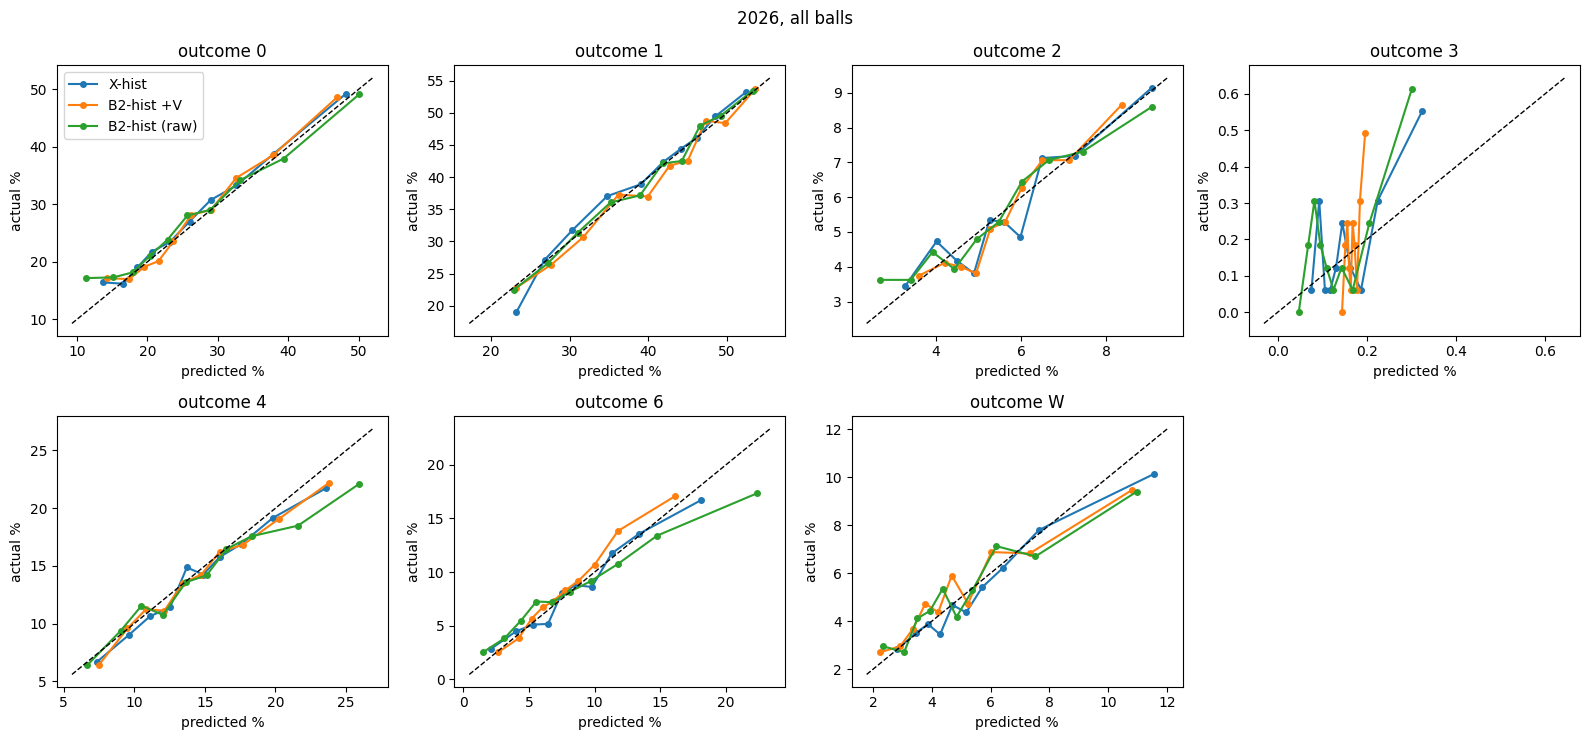

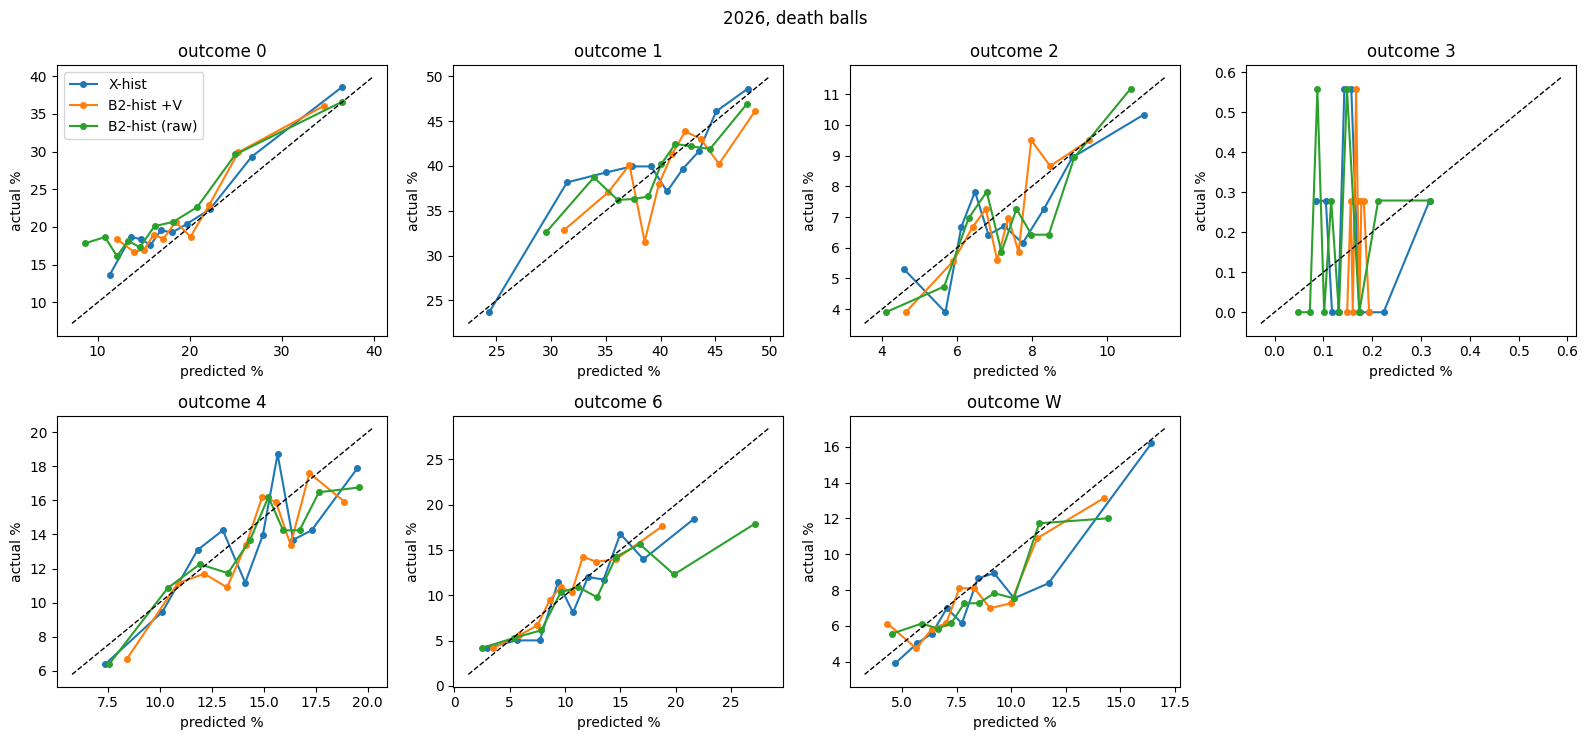

ECE (points), 2026 all balls


,0,1,2,3,4,6,W
B2-hist (raw),1.59,0.81,0.40,0.10,1.17,1.29,0.71
B2-hist +V,1.16,1.31,0.37,0.10,0.69,0.67,0.64
X-hist,1.03,1.09,0.46,0.09,0.81,0.67,0.38


ECE (points), 2026 death balls


,0,1,2,3,4,6,W
B2-hist (raw),4.17,1.71,0.88,0.17,1.33,2.60,1.18
B2-hist +V,2.57,2.55,0.72,0.16,1.34,0.95,1.09
X-hist,2.23,2.43,0.88,0.21,1.85,1.92,1.05


In [13]:
# ===== T12. Calibration on 2026 (COPY-PASTE) =====
NAMES = ['0', '1', '2', '3', '4', '6', 'W']
B25 = pd.read_parquet(DATA + 'bundle_2025.parquet')
y25, dth25 = B25['y'].to_numpy().astype(int), B25['death'].to_numpy()
P25 = {'X-hist': B25[[f'px_{k}' for k in range(7)]].to_numpy(), 'B2-hist +V': B25[[f'pl_{k}' for k in range(7)]].to_numpy()}

def share(y, m): return 100 * np.bincount(y[m], minlength=7) / m.sum()
def gap(Pm, y, m): return 100 * Pm[m].mean(axis=0) - share(y, m)

for title, m25, m26 in [('All balls', np.ones(len(y25), bool), ALL26), ('Death balls', dth25, dth26)]:
    t = pd.DataFrame({'actual 2025': share(y25, m25), 'actual 2026': share(y26, m26)}, index=NAMES)
    for name in ['X-hist', 'B2-hist +V']:
        t[f'{name} gap 2025'] = gap(P25[name], y25, m25)
        t[f'{name} gap 2026'] = gap(P[name], y26, m26)
    t['B2-hist raw gap 2026'] = gap(P['B2-hist (raw)'], y26, m26)
    t['B1 gap 2026'] = gap(P['B1'], y26, m26)
    print(title, '(points; gap = predicted - actual)'); display(t.round(2))

print('X-hist 2026 gaps with 95% match-bootstrap intervals (all balls)')
xg = []
for k, nm in enumerate(NAMES):
    g_, lo, hi, _, _ = slice_paired(P['X-hist'][:, k], (y26 == k).astype(float), ALL26, match26)
    xg.append({'outcome': nm, 'gap': 100 * g_, 'low': 100 * lo, 'high': 100 * hi, 'clear': '*' if (hi < 0 or lo > 0) else ''})
display(pd.DataFrame(xg).set_index('outcome').round(2))

def reliability(Pm, y, k, n_bins=10):
    p, hit = Pm[:, k], (y == k)
    bins = np.array_split(np.argsort(p), n_bins)
    pred = np.array([p[b].mean() for b in bins]); obs = np.array([hit[b].mean() for b in bins])
    sizes = np.array([len(b) for b in bins])
    return pred, obs, np.sum(sizes * np.abs(pred - obs)) / sizes.sum()

def plot_reliability(models, y, mask, title):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7.5)); ece = {}
    for k, ax in zip(range(7), axes.flat):
        for name, Pm in models.items():
            pred, obs, e = reliability(Pm[mask], y[mask], k)
            ax.plot(100 * pred, 100 * obs, 'o-', ms=4, label=name); ece[(name, NAMES[k])] = 100 * e
        lo = min(ax.get_xlim()[0], ax.get_ylim()[0]); hi = max(ax.get_xlim()[1], ax.get_ylim()[1])
        ax.plot([lo, hi], [lo, hi], 'k--', lw=1)
        ax.set_title(f'outcome {NAMES[k]}'); ax.set_xlabel('predicted %'); ax.set_ylabel('actual %')
    axes.flat[0].legend(); axes.flat[7].axis('off'); fig.suptitle(title); plt.tight_layout(); plt.show()
    return pd.Series(ece).unstack()[NAMES].round(2)

final = {'X-hist': P['X-hist'], 'B2-hist +V': P['B2-hist +V'], 'B2-hist (raw)': P['B2-hist (raw)']}
E_all = plot_reliability(final, y26, ALL26, '2026, all balls')
E_dth = plot_reliability(final, y26, dth26, '2026, death balls')
print('ECE (points), 2026 all balls');   display(E_all)
print('ECE (points), 2026 death balls'); display(E_dth)
pd.concat({'all': E_all, 'death': E_dth}).to_csv(DATA + 'ece_2026.csv')

In [14]:
# ===== A0. Load one season's bundle (COPY-PASTE) =====
YEAR = 2026                                              # 2025 reproduces the old tables
B = pd.read_parquet(DATA + f'bundle_{YEAR}.parquet')
y = B['y'].to_numpy().astype(int)
P_x, P_l, P_b1 = (B[[f'p{t}_{k}' for k in range(7)]].to_numpy() for t in ('x', 'l', 'b1'))
i = np.arange(len(y))
LX, LL, LB = (-np.log(Pm[i, y]) for Pm in (P_x, P_l, P_b1))
match = B['match_id'].to_numpy()
print(YEAR, len(B), LX.mean().round(4), LL.mean().round(4), LB.mean().round(4))   # 2026: 16282 and T7's three log-losses

RUNS = np.array([0, 1, 2, 3, 4, 6, 0], float)
runs_act, runs_exp = RUNS[y], P_x @ RUNS
six_act, six_exp = (y == 5).astype(float), P_x[:, 5]
wkt_act, wkt_exp = (y == 6).astype(float), P_x[:, 6]
bat, bowl = B['batter'].to_numpy(), B['bowler'].to_numpy()
print('runs per ball, expected vs actual:', runs_exp.mean().round(3), runs_act.mean().round(3))   # 2025 was 1.615 vs 1.554

2026 16282 1.4787 1.4813 1.5204
runs per ball, expected vs actual: 1.609 1.577


In [17]:
def slice_paired(la, lb, mask, match, n_boot=2000, z_bonf=3.254, seed=0):
    """Mean of (la - lb) over the slice, 95% match-bootstrap interval, SE, and the Bonferroni flag."""
    diff, m = (la - lb)[mask], match[mask]
    codes, _ = pd.factorize(m)
    s, c = np.bincount(codes, weights=diff), np.bincount(codes)
    idx = np.random.default_rng(seed).integers(0, len(s), size=(n_boot, len(s)))
    boot = s[idx].sum(axis=1) / c[idx].sum(axis=1)
    mean, se = diff.mean(), boot.std()
    low, high = np.percentile(boot, [2.5, 97.5])
    return mean, low, high, se, abs(mean) > z_bonf * se

In [18]:
def player_table(who, min_balls):
    rows = []
    for p in pd.unique(who):
        m = who == p
        n = int(m.sum())
        if n < min_balls:
            continue
        A = slice_paired(LX, LB, m, match)
        R = slice_paired(runs_act, runs_exp, m, match)
        S = slice_paired(six_act, six_exp, m, match)
        W = slice_paired(wkt_act, wkt_exp, m, match)
        rows.append({'player': p, 'balls': n, 'matches': len(np.unique(match[m])),
                     'gain vs B1': A[0], 'gain low': A[1], 'gain high': A[2],
                     'LL X-hist': LX[m].mean(),
                     'SR above exp': 100 * R[0], 'SR low': 100 * R[1], 'SR high': 100 * R[2],
                     'runs above exp': n * R[0], 'sixes above exp': n * S[0],
                     'wkts above exp': n * W[0], 'wkts low': n * W[1], 'wkts high': n * W[2]})
    return pd.DataFrame(rows).set_index('player')

In [19]:
BAT, BOWL = player_table(bat, 150), player_table(bowl, 120)
print(YEAR, ':', len(BAT), 'batters and', len(BOWL), 'bowlers qualify')
def top(df, col, asc, cols, title, n=10):
    print(title); display(df.sort_values(col, ascending=asc).head(n)[['balls'] + cols].round(3))
A_cols = ['gain vs B1', 'gain low', 'gain high']
top(BAT, 'gain vs B1', True,  A_cols, '(A) Batters the model reads best')
top(BAT, 'gain vs B1', False, A_cols, '(A) Batters the model reads least')
top(BAT, 'LL X-hist', True,  ['LL X-hist'], '(B) Most predictable batters')
top(BAT, 'LL X-hist', False, ['LL X-hist'], '(B) Least predictable batters')
C_bat = ['SR above exp', 'SR low', 'SR high', 'runs above exp', 'sixes above exp']
top(BAT, 'runs above exp', False, C_bat, '(C) Batters who beat the model most')
top(BAT, 'runs above exp', True,  C_bat, '(C) Batters the model over-rated most')
top(BOWL, 'gain vs B1', True,  A_cols, '(A) Bowlers the model reads best')
top(BOWL, 'gain vs B1', False, A_cols, '(A) Bowlers the model reads least')
C_bowl = ['runs above exp', 'SR above exp', 'wkts above exp', 'wkts low', 'wkts high']
top(BOWL, 'runs above exp', True,  C_bowl, '(C) Bowlers who conceded least vs expected')
top(BOWL, 'wkts above exp', False, C_bowl, '(C) Bowlers with most wickets above expected')
BAT.to_csv(DATA + f'players_bat_{YEAR}.csv'); BOWL.to_csv(DATA + f'players_bowl_{YEAR}.csv')

2026 : 44 batters and 61 bowlers qualify
(A) Batters the model reads best


,balls,gain vs B1,gain low,gain high
player,,,,
V Suryavanshi,312,-0.189,-0.272,-0.105
FH Allen,156,-0.176,-0.224,-0.124
Abhishek Sharma,275,-0.127,-0.192,-0.080
Priyansh Arya,171,-0.121,-0.199,-0.044
RD Rickelton,236,-0.095,-0.144,-0.045
TM Head,240,-0.089,-0.147,-0.037
RM Patidar,228,-0.078,-0.144,-0.002
D Ferreira,177,-0.073,-0.163,-0.015
Ishan Kishan,330,-0.066,-0.104,-0.028


(A) Batters the model reads least


,balls,gain vs B1,gain low,gain high
player,,,,
SA Yadav,180,0.010,-0.043,0.046
A Raghuvanshi,280,-0.002,-0.010,0.007
Washington Sundar,249,-0.002,-0.027,0.024
YBK Jaiswal,248,-0.006,-0.043,0.031
Sameer Rizvi,171,-0.007,-0.061,0.045
T Stubbs,216,-0.009,-0.026,0.015
RD Gaikwad,272,-0.009,-0.043,0.022
RR Pant,216,-0.011,-0.031,0.007
JC Buttler,345,-0.014,-0.038,0.006


(B) Most predictable batters


,balls,LL X-hist
player,,
T Stubbs,216,1.339
AK Markram,164,1.350
AM Rahane,242,1.383
Tilak Varma,236,1.403
Naman Dhir,203,1.404
RK Singh,197,1.406
RD Gaikwad,272,1.430
A Raghuvanshi,280,1.433
RR Pant,216,1.437


... (10 outputs left out)

(C) Bowlers who conceded least vs expected


,balls,runs above exp,SR above exp,wkts above exp,wkts low,wkts high
player,,,,,,
L Ngidi,248,-106.741,-43.041,-3.044,-9.853,4.343
B Kumar,354,-91.264,-25.781,7.638,-3.520,18.550
SP Narine,306,-89.226,-29.159,0.377,-3.351,3.572
Sakib Hussain,252,-78.676,-31.221,-0.804,-5.266,5.241
E Malinga,326,-76.544,-23.480,2.079,-5.941,11.749
Prince Yadav,288,-76.052,-26.407,-0.962,-8.682,8.019
Rasikh Salam,233,-53.298,-22.875,1.989,-3.946,8.512
JJ Bumrah,276,-50.696,-18.368,-12.739,-18.032,-7.303
JO Holder,230,-46.597,-20.260,5.949,-2.579,14.556


(C) Bowlers with most wickets above expected


,balls,runs above exp,SR above exp,wkts above exp,wkts low,wkts high
player,,,,,,
K Rabada,388,20.490,5.281,9.375,0.085,18.285
B Kumar,354,-91.264,-25.781,7.638,-3.520,18.550
JC Archer,348,-12.582,-3.616,7.265,-0.787,15.421
C Bosch,121,15.263,12.614,6.976,1.571,12.534
JO Holder,230,-46.597,-20.260,5.949,-2.579,14.556
MA Starc,132,8.488,6.430,5.309,-0.148,10.593
SN Thakur,120,17.614,14.678,4.129,-0.885,9.196
M Prasidh Krishna,234,40.977,17.511,3.984,-2.616,11.124
J Overton,168,-26.527,-15.790,3.548,-3.595,9.968


In [20]:
for kind in ('bat', 'bowl'):
    a = pd.read_csv(DATA + f'players_{kind}_2025.csv', index_col='player')[['gain vs B1', 'balls']]
    b = pd.read_csv(DATA + f'players_{kind}_2026.csv', index_col='player')[['gain vs B1', 'balls']]
    both = a.join(b, lsuffix=' 2025', rsuffix=' 2026', how='inner')
    rho = both['gain vs B1 2025'].corr(both['gain vs B1 2026'], method='spearman')
    print(f'{kind}: {len(both)} players in both seasons | Spearman rho of gain vs B1: {rho:.2f}')
    display(both.sort_values('gain vs B1 2026').round(3).head(10))

bat: 32 players in both seasons | Spearman rho of gain vs B1: 0.31


,gain vs B1 2025,balls 2025,gain vs B1 2026,balls 2026
player,,,,
Abhishek Sharma,-0.084,225,-0.127,275
Priyansh Arya,-0.088,218,-0.121,171
RD Rickelton,-0.038,253,-0.095,236
TM Head,-0.031,226,-0.089,240
RM Patidar,-0.014,199,-0.078,228
Ishan Kishan,-0.024,231,-0.066,330
V Kohli,-0.039,451,-0.062,404
RG Sharma,-0.034,271,-0.059,173
R Parag,-0.064,235,-0.056,185


bowl: 33 players in both seasons | Spearman rho of gain vs B1: -0.11


,gain vs B1 2025,balls 2025,gain vs B1 2026,balls 2026
player,,,,
SN Thakur,-0.016,204,-0.091,120
DS Rathi,-0.013,312,-0.077,210
Avesh Khan,-0.046,284,-0.072,148
Rashid Khan,-0.046,306,-0.063,341
A Kamboj,-0.014,129,-0.062,302
M Prasidh Krishna,-0.007,330,-0.060,234
Kuldeep Yadav,-0.004,306,-0.055,222
AR Patel,-0.055,204,-0.055,264
VG Arora,-0.059,231,-0.054,228
